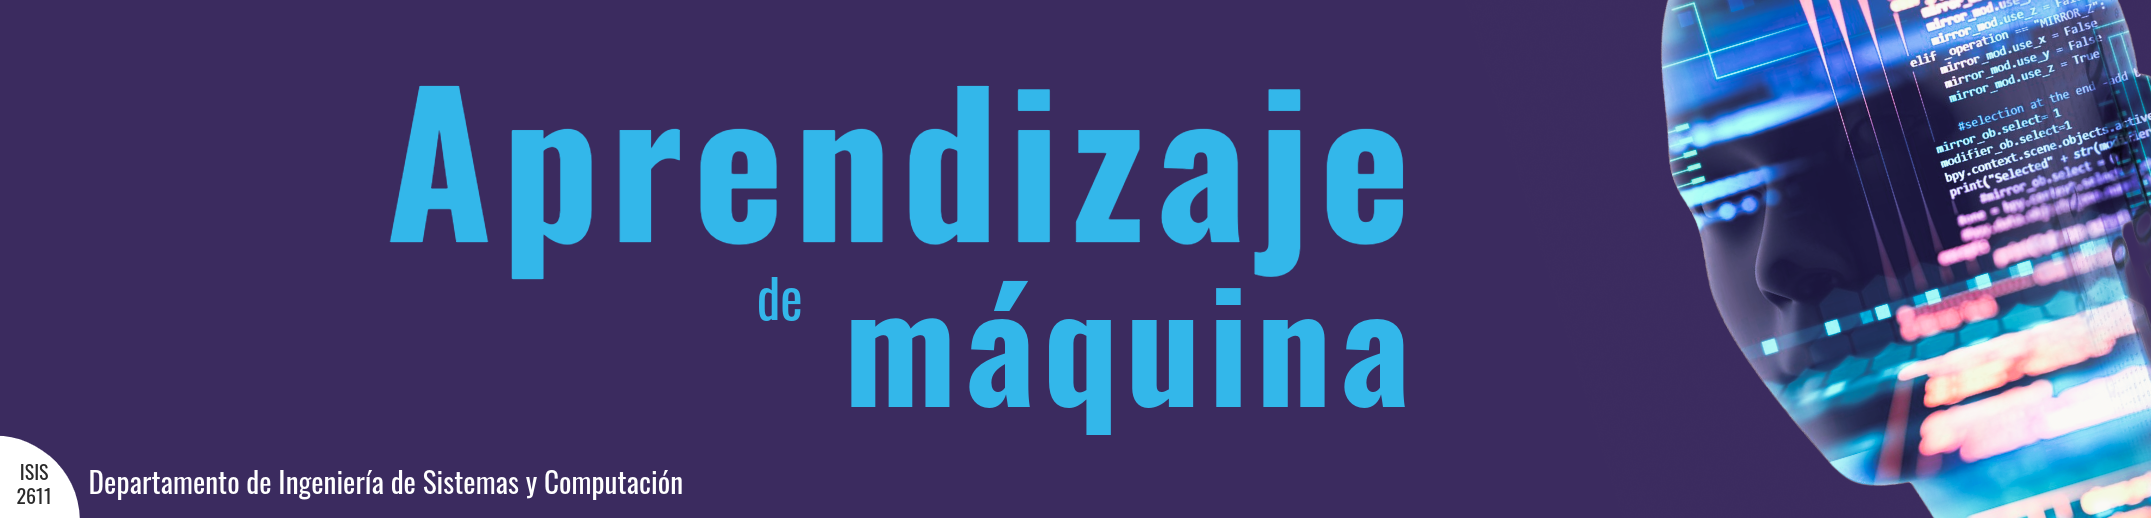

# Redes Neuronales Convolucionales (CNN)

Las Redes Neuronales Convolucionales (CNN) son un tipo de red neuronal especialmente diseñado para procesar datos con estructura espacial, como las imágenes. A diferencia de las redes completamente conectadas (MLP), que tratan cada píxel como una característica independiente, las CNN aprovechan las relaciones espaciales entre píxeles vecinos para identificar patrones como bordes, texturas y formas. Para ello, utilizan operaciones llamadas convoluciones, que permiten extraer características locales y reutilizar los mismos filtros en distintas regiones de la imagen.

| Sección | Contenido |
|---------|-----------|
| 1 | Configuración del entorno |
| 2 | El problema con las MLP para imágenes |
| 3 | La operación de convolución |
| 4 | Padding y stride |
| 5 | Capas clave: MaxPooling, BatchNorm, Dropout |
| 6 | Arquitectura completa de una CNN |
| 7 | Caso práctico: CIFAR-10 desde cero |

## 1. Configuración del entorno

Se recomienda GPU en Google Colab: *Entorno de ejecución → Cambiar tipo → T4 GPU*.

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import matplotlib.patches as mpatches

from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import ipywidgets as widgets
from tensorflow import keras
from tensorflow.keras import layers, models

# Verificar disponibilidad de GPU
print(f'TensorFlow: {tf.__version__}')
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    print(f'GPU disponible: {gpus}')
else:
    print('GPU no disponible. TensorFlow utilizará CPU.')
plt.style.use('seaborn-v0_8-whitegrid')

## 2. El problema con las MLP para imágenes

### 2.1 Lo que el MLP ignora de una imagen

Un MLP recibe la imagen como un vector plano de píxeles. Para una imagen
de 32×32×3 eso son **3.072 números** sin ninguna información de vecindad.

Consecuencias directas:

1. **No detecta patrones locales**: el MLP no sabe que el píxel (10,10) está
   junto al (10,11). Un borde diagonal existe en el espacio 2D, no en un vector.
2. **El orden de los píxeles le es indiferente**: si aplicamos *la misma* permutación fija
   a todas las imágenes (entrenamiento y test) y lo entrenamos así, el MLP aprende igual de bien.
   La estructura espacial nunca fue parte de lo que usaba.
3. **Explosión de parámetros**: la primera capa de un MLP con 256 neuronas
   sobre imágenes 32×32×3 tiene 3.072 × 256 + 256 = **786.688 parámetros** (pesos + sesgos) — y eso
   es solo la primera capa.

Las CNN atacan estos problemas con dos ideas: **conexiones locales** (cada salida mira solo un
parche pequeño) y **pesos compartidos** (el mismo filtro se aplica en todas las posiciones).

In [ ]:
# Cargamos CIFAR-10 y mostramos una imagen original vs. con columnas permutadas
(X_train, y_train), (X_test, y_test) = keras.datasets.cifar10.load_data()
X_train = X_train.astype('float32') / 255.0
X_test  = X_test.astype('float32') / 255.0

class_names = ['avión','auto','pájaro','gato','venado',
               'perro','rana','caballo','barco','camión']

img = X_train[0]
np.random.seed(42)
perm = np.random.permutation(32)     # permutación de columnas
img_perm = img[:, perm, :]           # columnas barajadas

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(img); axes[0].set_title('Original', fontweight='bold')
axes[0].axis('off')
axes[1].imshow(img_perm); axes[1].set_title('Columnas permutadas', fontweight='bold')
axes[1].axis('off')

# Canal rojo del original vs. permutado — para ver la diferencia en valores
axes[2].plot(img[:, 16, 0], label='Original (col 16)', color='#4C6EF5', lw=2)
axes[2].plot(img_perm[:, 16, 0], label='Permutada (col 16)', color='#FF6B6B', lw=2)
axes[2].set_title('Canal rojo, columna 16', fontweight='bold')
axes[2].set_xlabel('Fila'); axes[2].set_ylabel('Intensidad')
axes[2].legend(fontsize=9)

plt.suptitle('Mismos 3.072 valores en distinto orden: para un MLP ambas contienen la misma información',
             fontsize=10, fontweight='bold')
plt.tight_layout(); plt.show()

print('Clase real:', class_names[int(y_train[0, 0])])
print('Un MLP plano (Flatten → Dense) pierde toda la información de vecindad espacial.')
print('Una CNN opera sobre ventanas 2D y preserva esa relación.')

> **Idea central**: la CNN **no aplana** la imagen. Opera sobre parches 2D de
> píxeles vecinos, detectando el mismo patrón (un borde, una curva, una textura)
> sin importar en qué posición de la imagen esté — eso se llama **equivarianza
> a la traslación**.

####  Ejercicio 1 — Impacto de la permutación en el MLP

1. Entrena un MLP simple (2 capas densas) sobre CIFAR-10 con las imágenes originales.
   Luego aplica la misma permutación de columnas a todo el dataset (train y test) y
   vuelve a entrenarlo. ¿Cambia el accuracy? ¿Por qué sí o por qué no?
2. Calcula cuántos parámetros tiene la primera capa densa de un MLP con 256 neuronas
   sobre imágenes 32×32×3. ¿Cuántos tiene la primera capa Conv2D(32, (3,3)) equivalente?
3. La equivarianza a la traslación significa que si un gato se mueve 5 píxeles a la
   derecha, la representación también se desplaza 5 píxeles. ¿Es eso lo mismo que
   invarianza (producir exactamente la misma salida)? ¿Qué capa CNN añade invarianza?

## 3. La operación de convolución

### 3.1 ¿Qué hace matemáticamente una convolución?

Una **convolución** (técnicamente, correlación cruzada) desliza un pequeño filtro
llamado **kernel** sobre la imagen y en cada posición calcula el producto punto
entre el kernel y el parche local de la imagen:

$$S(i,j) = \sum_m \sum_n I(i+m,\, j+n) \cdot K(m,n)$$

donde $I$ es la imagen de entrada, $K$ es el kernel y $S$ es el mapa de salida.

El resultado es un **mapa de características** (*feature map*): una imagen donde
cada píxel indica qué tan fuertemente el patrón del kernel aparece en esa posición.

### 3.2 ¿Qué aprende el kernel?

| Kernel manual | Efecto en la imagen | Uso típico |
|--------------|---------------------|------------|
| $\begin{bmatrix}0&-1&0\\-1&5&-1\\0&-1&0\end{bmatrix}$ | Realza detalles (sharpen) | Nitidez |
| $\begin{bmatrix}.06&.13&.06\\.13&.25&.13\\.06&.13&.06\end{bmatrix}$ | Difumina (aprox. gaussiano) | Reducción de ruido |
| $\begin{bmatrix}-1&0&1\\-2&0&2\\-1&0&1\end{bmatrix}$ | Bordes verticales (Sobel) | Detección de contornos |
| $\begin{bmatrix}-1&-2&-1\\0&0&0\\1&2&1\end{bmatrix}$ | Bordes horizontales (Sobel) | Detección de contornos |

> **Diferencia clave**: en procesamiento de imagen clásico los kernels se diseñan
> manualmente. En una CNN, los kernels son **parámetros aprendidos** — la red
> descubre automáticamente qué patrones son útiles para la tarea de clasificación.

### 3.3 Animación: cómo se desliza el kernel

La siguiente animación muestra el proceso completo de convolución sobre una
imagen 6×6 con un kernel 3×3. El rectángulo naranja indica la posición actual
del kernel, y el mapa de características se va construyendo valor a valor.

In [ ]:
# ─── Animación: convolución deslizante ──────────────────────────────────────
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from matplotlib.patches import Rectangle
from IPython.display import HTML

plt.rcParams['animation.embed_limit'] = 50   # MB: evita que se descarten cuadros

# Imagen 6×6 y kernel 3×3 (detección de borde vertical Sobel)
IMG = np.array([
    [1,0,0,1,1,0],
    [1,0,0,1,1,0],
    [1,0,0,1,1,0],
    [0,1,1,0,0,1],
    [0,1,1,0,0,1],
    [1,0,0,1,0,1],
], dtype=float)

KERNEL = np.array([
    [-1, 0, 1],
    [-2, 0, 2],
    [-1, 0, 1],
], dtype=float)   # Sobel vertical

H, W = IMG.shape
K = KERNEL.shape[0]
OUT_H, OUT_W = H - K + 1, W - K + 1

# Precomputar todos los valores del feature map
feat_map = np.zeros((OUT_H, OUT_W))
for i in range(OUT_H):
    for j in range(OUT_W):
        feat_map[i, j] = np.sum(IMG[i:i+K, j:j+K] * KERNEL)

# Secuencia de posiciones
positions = [(i, j) for i in range(OUT_H) for j in range(OUT_W)]
N_POS = len(positions)
N_FPP = 6   # cuadros por posición
N_REP = 8

fig_conv, axes_c = plt.subplots(1, 3, figsize=(14, 5))
fig_conv.patch.set_facecolor('#1A1A2E')
for ax in axes_c:
    ax.set_facecolor('#1A1A2E')

# Panel 1: imagen de entrada
axes_c[0].imshow(IMG, cmap='Blues', vmin=0, vmax=1)
axes_c[0].set_title('Imagen de entrada (6×6)', color='white', fontweight='bold')
axes_c[0].tick_params(colors='white')
for sp in axes_c[0].spines.values(): sp.set_edgecolor('#333355')
for ii in range(H):
    for jj in range(W):
        axes_c[0].text(jj, ii, f'{int(IMG[ii,jj])}', ha='center', va='center',
                        fontsize=11, color='white' if IMG[ii,jj] > 0.5 else '#1A1A2E', fontweight='bold')
rect_kernel = Rectangle((-0.5, -0.5), K, K, linewidth=3,
                          edgecolor='#F39C12', facecolor='#F39C12', alpha=0.25)
axes_c[0].add_patch(rect_kernel)

# Panel 2: kernel
axes_c[1].imshow(KERNEL, cmap='RdYlGn', vmin=-2, vmax=2)
axes_c[1].set_title('Kernel Sobel vertical (3×3)', color='white', fontweight='bold')
axes_c[1].tick_params(colors='white')
for ii in range(K):
    for jj in range(K):
        axes_c[1].text(jj, ii, f'{int(KERNEL[ii,jj])}', ha='center', va='center',
                        fontsize=13, color='black', fontweight='bold')

# Panel 3: feature map construyéndose
feat_display = np.full((OUT_H, OUT_W), np.nan)
im_feat = axes_c[2].imshow(feat_display, cmap='RdYlGn',
                             vmin=feat_map.min(), vmax=feat_map.max())
axes_c[2].set_title('Feature map (4×4) construyéndose', color='white', fontweight='bold')
axes_c[2].tick_params(colors='white')
txt_feat = {}
for ii in range(OUT_H):
    for jj in range(OUT_W):
        t = axes_c[2].text(jj, ii, '', ha='center', va='center',
                            fontsize=11, color='black', fontweight='bold')
        txt_feat[(ii,jj)] = t

txt_calc = fig_conv.text(0.5, 0.01, '', ha='center', color='#F39C12',
                          fontsize=10, fontweight='bold')

def update_conv(frame):
    if frame < N_REP:
        rect_kernel.set_xy((-0.5, -0.5))
        txt_calc.set_text('Kernel listo — comenzando la convolución...')
        return [rect_kernel, im_feat]

    f = frame - N_REP
    pos_idx = min(f // N_FPP, N_POS - 1)
    t_frac  = min((f % N_FPP) / (N_FPP - 1), 1.0)
    i_pos, j_pos = positions[pos_idx]

    # Mover rectángulo en la imagen
    rect_kernel.set_xy((j_pos - 0.5, i_pos - 0.5))
    rect_kernel.set_alpha(0.25 + 0.3 * t_frac)

    # Rellenar feature map hasta la posición actual
    feat_parcial = np.full((OUT_H, OUT_W), np.nan)
    for k_idx in range(pos_idx + (1 if t_frac >= 0.9 else 0)):
        ii, jj = positions[k_idx]
        feat_parcial[ii, jj] = feat_map[ii, jj]
    im_feat.set_data(feat_parcial)

    # Texto del cálculo actual
    parche = IMG[i_pos:i_pos+K, j_pos:j_pos+K]
    val_actual = feat_map[i_pos, j_pos]
    txt_calc.set_text(
        f'Posición ({i_pos},{j_pos}): Σ(parche × kernel) = {val_actual:.1f}'
    )

    # Valores en el feature map
    for k_idx in range(pos_idx + 1):
        ii, jj = positions[k_idx]
        txt_feat[(ii,jj)].set_text(f'{feat_map[ii,jj]:.0f}')

    return [rect_kernel, im_feat]

TOTAL_CONV = N_REP + N_POS * N_FPP + 15
ani_conv = FuncAnimation(fig_conv, update_conv, frames=TOTAL_CONV,
                          interval=140, blit=False, repeat=True)
plt.tight_layout(pad=1.5)
plt.close(fig_conv)   # evita que aparezca además una figura estática
HTML(ani_conv.to_jshtml())

> **Qué observar:**
> - El kernel 3×3 se posiciona sobre cada parche posible de la imagen 6×6.
> - En cada posición calcula el producto elemento a elemento y lo suma.
> - El valor resultante mide 'qué tan parecido es ese parche al patrón del kernel'.
> - Este kernel Sobel detecta **bordes verticales**: calcula (columna derecha − columna izquierda).
>   Los valores **positivos (verde)** indican una transición de oscuro a claro de izquierda a derecha;
>   los **negativos (rojo)**, la transición contraria. Cerca de 0 (amarillo): no hay borde vertical.
> - **Verifica a mano** el valor de la posición (0,0) del feature map.

## 4. Padding, Stride y parámetros de la convolución

### 4.1 Padding: controlar el tamaño de salida

Sin padding, cada convolución encoge el feature map:
$(H_{in}, W_{in}) \rightarrow (H_{in} - K + 1, W_{in} - K + 1)$.

El **padding** añade filas/columnas de ceros alrededor de la imagen para
controlar ese efecto:

| Tipo | Descripción | Cuándo usar |
|------|-------------|-------------|
| **valid** (sin padding) | La salida es más pequeña | Cuando se quiere reducir dimensión |
| **same** (padding=K//2, K impar) | Con stride 1, la salida tiene el mismo tamaño | Para preservar dimensiones en capas intermedias |

Keras usa `padding='same'` o `padding='valid'`.

### 4.2 Stride: saltar posiciones

El **stride** controla cuántos píxeles avanza el kernel en cada paso.

| Stride | Efecto | Tamaño de salida (`valid`) | Tamaño de salida (`same`) |
|--------|--------|----------------------------|---------------------------|
| 1 | Posición a posición | $H - K + 1$ | $H$ |
| 2 | Salta una posición | $\lfloor (H - K)/2 \rfloor + 1$ | $\lceil H/2 \rceil$ |
| 3 | Salta dos posiciones | $\lfloor (H - K)/3 \rfloor + 1$ | $\lceil H/3 \rceil$ |

Una convolución con stride=2 reduce el tamaño igual que un MaxPooling 2×2, pero la operación es
distinta: en lugar de tomar un máximo fijo, aplica pesos aprendidos.
En arquitecturas modernas (ResNet, EfficientNet) se prefiere stride=2
a MaxPooling porque el modelo aprende cómo reducir.

### 4.3 Fórmula general del tamaño de salida

$$H_{out} = \left\lfloor \frac{H_{in} + 2P - K}{S} \right\rfloor + 1$$

donde $P$ = padding, $K$ = tamaño del kernel, $S$ = stride.

In [ ]:
def visualizar_padding_stride(padding='same', stride=1, kernel=3):
    H_in = 8
    P = kernel // 2 if padding == 'same' else 0
    H_out = (H_in + 2*P - kernel) // stride + 1

    H_pad = H_in + 2*P
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    # Panel 1: imagen con padding
    img_p = np.ones((H_pad, H_pad)) * 0.15
    img_p[P:P+H_in, P:P+H_in] = 0.6
    axes[0].imshow(img_p, cmap='Blues', vmin=0, vmax=1)
    axes[0].set_title(f'Imagen {H_in}×{H_in} con padding={padding} (P={P})\n'
                      f'Tamaño con padding: {H_pad}×{H_pad}',
                      fontweight='bold')
    axes[0].set_xticks(np.arange(-0.5, H_pad, 1), minor=True)
    axes[0].set_yticks(np.arange(-0.5, H_pad, 1), minor=True)
    axes[0].grid(which='minor', color='white', linewidth=0.8)
    # Kernel en la primera posición
    from matplotlib.patches import Rectangle
    rect = Rectangle((-0.5, -0.5), kernel, kernel, lw=2.5,
                      edgecolor='#F39C12', facecolor='#F39C12', alpha=0.3)
    axes[0].add_patch(rect)
    axes[0].text(kernel/2-0.5, kernel/2-0.5, 'K', ha='center', va='center',
                  fontsize=14, color='white', fontweight='bold')

    # Panel 2: feature map resultante
    feat_grid = np.zeros((H_out, H_out))
    for ii in range(H_out):
        for jj in range(H_out):
            y0 = ii * stride
            x0 = jj * stride
            feat_grid[ii, jj] = img_p[y0:y0+kernel, x0:x0+kernel].mean()
    axes[1].imshow(feat_grid, cmap='Blues', vmin=0, vmax=1)
    axes[1].set_title(f'Feature map resultante: {H_out}×{H_out}\n'
                      f'(stride={stride}, kernel={kernel}×{kernel})',
                      fontweight='bold')
    axes[1].set_xticks(np.arange(-0.5, H_out, 1), minor=True)
    axes[1].set_yticks(np.arange(-0.5, H_out, 1), minor=True)
    axes[1].grid(which='minor', color='white', linewidth=0.8)
    for ii in range(H_out):
        for jj in range(H_out):
            axes[1].text(jj, ii, f'{feat_grid[ii,jj]:.1f}', ha='center', va='center',
                          fontsize=9, color='black')

    plt.suptitle(f'Fórmula: H_out = floor((H_in + 2P - K) / S) + 1 = floor(({H_in} + {2*P} - {kernel}) / {stride}) + 1 = {H_out}',
                  fontsize=11, fontweight='bold')
    plt.tight_layout(); plt.show()

widgets.interact(
    visualizar_padding_stride,
    padding=widgets.ToggleButtons(options=['valid', 'same'], description='Padding:',
                                   style={'description_width':'80px','button_width':'80px'}),
    stride=widgets.IntSlider(value=1, min=1, max=3, step=1, description='Stride:',
                              continuous_update=False, style={'description_width':'60px'}),
    kernel=widgets.ToggleButtons(options=[3, 5, 7], description='Kernel size:',
                                  style={'description_width':'90px','button_width':'60px'}));

## 5. Capas clave: MaxPooling, BatchNorm y Dropout

### 5.1 MaxPooling: resumir y confirmar patrones

Después de detectar un patrón con una convolución, no necesitamos saber
exactamente en qué píxel estaba — solo que estaba *en esa región*.
**MaxPooling** resume una ventana (típicamente 2×2) tomando el valor máximo:

$$\text{MaxPool}(2×2) \text{ sobre } 4×4 \rightarrow 2×2 \quad (75\% \ \text{de reducción})$$

**Beneficios:**
- **Invarianza a la traslación local**: si el patrón se mueve 1 píxel, MaxPooling
  sigue reportando su presencia.
- **Reducción de dimensionalidad**: reduce el volumen de datos en 75% por aplicación.
- **Campo receptivo ampliado**: las capas siguientes 'ven' regiones más grandes.
- **Regularización (efecto leve)**: la red depende menos de la posición exacta de cada patrón.

MaxPooling no tiene parámetros entrenables.

### 5.2 Batch Normalization: estabilizar el aprendizaje

A medida que la red se hace profunda, las activaciones pueden crecer o colapsar
entre capas, lo que dificulta el entrenamiento. **BatchNorm** normaliza las activaciones
de cada canal usando la media y la varianza del mini-batch:

$$\hat{x}_i = \frac{x_i - \mu_B}{\sqrt{\sigma_B^2 + \epsilon}}$$

y luego aplica parámetros aprendibles $\gamma$ (escala) y $\beta$ (desplazamiento). En inferencia usa
promedios móviles de la media y la varianza; por eso aparecen parámetros *no entrenables* en `summary()`.

**Efectos prácticos:**
- Permite usar tasas de aprendizaje más altas.
- Actúa como regularizador ligero (reduce necesidad de Dropout).
- Hace el entrenamiento más estable y rápido.

> La explicación original fue que reduce el *internal covariate shift*. Trabajos posteriores
> (Santurkar et al., 2018) sugieren que su efecto principal es suavizar la superficie de pérdida.
> Para este curso bastan los efectos prácticos.

### 5.3 Dropout: apagar neuronas aleatoriamente

Dropout desactiva aleatoriamente una fracción $p$ de las neuronas durante
el entrenamiento. Cada neurona aprende a no depender de sus vecinas,
forzando representaciones más robustas.

> **Nota**: Keras usa *inverted dropout*. Durante el entrenamiento, las activaciones que sobreviven
> se multiplican por $1/(1-p)$ para conservar el valor esperado. En inferencia el Dropout **no hace
> nada**: todas las neuronas participan, sin reescalar.

In [ ]:
def visualizar_maxpool(pool_size=2, stride_pool=2):
    np.random.seed(7)
    feat_in = np.random.rand(6, 6)
    H_out = (6 - pool_size) // stride_pool + 1
    feat_out = np.zeros((H_out, H_out))
    pos_max  = {}
    for ii in range(H_out):
        for jj in range(H_out):
            ventana = feat_in[ii*stride_pool:ii*stride_pool+pool_size,
                               jj*stride_pool:jj*stride_pool+pool_size]
            feat_out[ii,jj] = ventana.max()
            idx = np.unravel_index(ventana.argmax(), ventana.shape)
            pos_max[(ii,jj)] = (ii*stride_pool+idx[0], jj*stride_pool+idx[1])

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    im0 = axes[0].imshow(feat_in, cmap='YlOrRd', vmin=0, vmax=1)
    axes[0].set_title(f'Feature map entrada (6×6)', fontweight='bold')
    for ii in range(6):
        for jj in range(6): axes[0].text(jj, ii, f'{feat_in[ii,jj]:.2f}', ha='center', va='center', fontsize=9)
    # Dibujar ventanas del pool
    cmap_v = ['#4C6EF5','#2ECC71','#FF6B6B','#F39C12']
    patch_idx = 0
    for ii in range(H_out):
        for jj in range(H_out):
            y0,x0 = ii*stride_pool-0.5, jj*stride_pool-0.5
            from matplotlib.patches import Rectangle
            rect = Rectangle((x0, y0), pool_size, pool_size, lw=2.5,
                              edgecolor=cmap_v[patch_idx % len(cmap_v)],
                              facecolor='none')
            axes[0].add_patch(rect)
            # Marcar el máximo con estrella
            r_max, c_max = pos_max[(ii,jj)]
            axes[0].scatter(c_max, r_max, s=200, marker='*',
                             color=cmap_v[patch_idx % len(cmap_v)], zorder=5)
            patch_idx += 1
    plt.colorbar(im0, ax=axes[0], shrink=0.8)

    im1 = axes[1].imshow(feat_out, cmap='YlOrRd', vmin=0, vmax=1)
    axes[1].set_title(f'Después de MaxPool {pool_size}×{pool_size} → {H_out}×{H_out}\n'
                      f'(★ = posición del máximo en cada ventana)', fontweight='bold')
    for ii in range(H_out):
        for jj in range(H_out):
            axes[1].text(jj, ii, f'{feat_out[ii,jj]:.2f}', ha='center', va='center',
                          fontsize=12, fontweight='bold')
    plt.colorbar(im1, ax=axes[1], shrink=0.8)

    reduccion = (1 - (H_out**2)/(6**2))*100
    plt.suptitle(f'MaxPooling {pool_size}×{pool_size}: 36 valores → {H_out**2} ({reduccion:.0f}% de reducción)',
                  fontsize=11, fontweight='bold')
    plt.tight_layout(); plt.show()

widgets.interact(
    visualizar_maxpool,
    pool_size=widgets.ToggleButtons(options=[2, 3], description='Pool size:',
                                     style={'description_width':'80px','button_width':'60px'}),
    stride_pool=widgets.IntSlider(value=2, min=1, max=3, step=1, description='Stride:',
                                   continuous_update=False, style={'description_width':'60px'}));

## 6. Arquitectura completa: jerarquía de características

### 6.1 De bordes a objetos

La magia de las CNNs está en la **jerarquía de abstracción** que emerge
automáticamente al apilar capas convolucionales:

```
Primeras capas:     bordes orientados, manchas de color
Capas intermedias:  esquinas, texturas, combinaciones de bordes
Capas profundas:    partes de objetos (ruedas, ojos, alas)
Dense:              combina esas evidencias para clasificar
```

Cada capa ve el mundo a través de los 'ojos' de la capa anterior.
Esto es lo que permite aprender representaciones tan ricas a partir de píxeles crudos.

### 6.2 Anatomía de un bloque CNN

Un bloque convolucional típico tiene esta estructura:

```
Conv2D(filtros, kernel, padding='same')  → extrae patrones
    ↓
BatchNormalization()                      → estabiliza activaciones
    ↓
Activation('relu')                        → no-linealidad
    ↓   (Conv → BN → ReLU se puede repetir 1-2 veces)
MaxPooling2D(2,2)                         → reduce + invarianza local
    ↓
Dropout(p)                                → regularización
```

Una CNN completa apila 2-5 de estos bloques, con el número de filtros
típicamente doblándose en cada bloque (32 → 64 → 128 → 256).

## 7. Caso práctico: CIFAR-10 desde cero

### 7.1 El dataset CIFAR-10

CIFAR-10 contiene **60.000 imágenes a color** de 32×32 píxeles en 10 categorías.
Es el benchmark estándar para comparar arquitecturas CNN.

| Split | Imágenes | Uso |
|-------|----------|-----|
| Train | 45.000 | Entrenamiento |
| Validación | 5.000 (separadas del train) | Monitorear el entrenamiento y decidir cuándo parar |
| Test | 10.000 | Evaluación final, **una sola vez** |

> **¿Por qué no usar el test como validación?** Los *callbacks* `EarlyStopping` y `ReduceLROnPlateau`
> toman decisiones mirando la pérdida de validación. Si la validación fuera el test, el test participaría
> en la selección del modelo y su accuracy dejaría de ser una estimación honesta (*data snooping*).

In [ ]:
# Dataset ya cargado en sección 2 — exploración visual
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for i, ax in enumerate(axes.flat):
    idx = np.where(y_train.flatten() == i)[0][0]
    ax.imshow(X_train[idx])
    ax.set_title(f'{class_names[i]}', fontweight='bold', fontsize=11)
    ax.axis('off')
plt.suptitle('CIFAR-10: un ejemplo por clase', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

# Distribución de clases
fig, ax = plt.subplots(figsize=(10, 4))
conteos = [np.sum(y_train == i) for i in range(10)]
bars = ax.bar(class_names, conteos, color='#4C6EF5', alpha=0.85, edgecolor='white')
ax.bar_label(bars, fontsize=9)
ax.set_title('Distribución de clases en train (balanceado: 5.000 por clase)',
              fontweight='bold')
ax.set_ylabel('Cantidad de imágenes')
plt.tight_layout(); plt.show()

### 7.2 Arquitectura del modelo baseline

Construimos una CNN con 3 bloques convolucionales. La arquitectura sigue
el patrón de la sección 6.2: (Conv → BatchNorm → ReLU) × 1-2 → MaxPool → Dropout.
El número de filtros dobla en cada bloque: 32 → 64 → 128.

In [ ]:
def construir_cnn_baseline():
    model = models.Sequential(name='CNN_Baseline')
    model.add(layers.Input(shape=(32, 32, 3)))

    # Bloque 1: bordes y manchas de color
    model.add(layers.Conv2D(32, (3,3), padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.Conv2D(32, (3,3), padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.MaxPooling2D((2,2)))  # 32×32 → 16×16
    model.add(layers.Dropout(0.2))

    # Bloque 2: texturas y combinaciones de bordes
    model.add(layers.Conv2D(64, (3,3), padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.Conv2D(64, (3,3), padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.MaxPooling2D((2,2)))  # 16×16 → 8×8
    model.add(layers.Dropout(0.3))

    # Bloque 3: patrones más complejos (partes de objetos)
    model.add(layers.Conv2D(128, (3,3), padding='same'))
    model.add(layers.BatchNormalization())
    model.add(layers.Activation('relu'))
    model.add(layers.MaxPooling2D((2,2)))  # 8×8 → 4×4
    model.add(layers.Dropout(0.4))

    # Clasificador
    model.add(layers.GlobalAveragePooling2D())   # 4×4×128 → 128
    model.add(layers.Dense(128, activation='relu'))
    model.add(layers.Dropout(0.5))
    model.add(layers.Dense(10, activation='softmax'))

    return model

cnn = construir_cnn_baseline()
cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
cnn.summary()

In [ ]:
# Separar 5.000 imágenes del entrenamiento para validación (estratificado)
from sklearn.model_selection import train_test_split
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train, test_size=5000, stratify=y_train, random_state=42)
print(f'Entrenamiento: {X_tr.shape[0]:,}  |  Validación: {X_val.shape[0]:,}  |  Test: {X_test.shape[0]:,}')

# Los callbacks guardan estado (mejor pérdida, contador de paciencia):
# cada entrenamiento debe recibir instancias nuevas.
def make_callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=7,
                                      restore_best_weights=True, verbose=1),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5,
                                          patience=3, verbose=1),
    ]

history_base = cnn.fit(
    X_tr, y_tr,
    epochs=20, batch_size=64,
    validation_data=(X_val, y_val),
    callbacks=make_callbacks(), verbose=1
)

In [ ]:
# Curvas de entrenamiento
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history_base.history['accuracy'], color='#4C6EF5', lw=2, label='Train')
axes[0].plot(history_base.history['val_accuracy'], color='#FF6B6B', lw=2,
              linestyle='--', label='Validación')
axes[0].set_title('Accuracy durante el entrenamiento', fontweight='bold')
axes[0].set_xlabel('Época'); axes[0].set_ylabel('Accuracy')
axes[0].legend(); axes[0].grid(alpha=0.4)

axes[1].plot(history_base.history['loss'], color='#4C6EF5', lw=2, label='Train')
axes[1].plot(history_base.history['val_loss'], color='#FF6B6B', lw=2,
              linestyle='--', label='Validación')
axes[1].set_title('Pérdida durante el entrenamiento', fontweight='bold')
axes[1].set_xlabel('Época'); axes[1].set_ylabel('Loss')
axes[1].legend(); axes[1].grid(alpha=0.4)

plt.suptitle('CNN Baseline — CIFAR-10', fontsize=13, fontweight='bold')
plt.tight_layout(); plt.show()

# Evaluación final: es la única vez que usamos el test
loss, acc = cnn.evaluate(X_test, y_test, verbose=0)
print(f'\nAccuracy en test: {acc:.4f} ({acc*100:.1f}%)')

### 7.3 Visualización de filtros y feature maps

¿Qué aprendió cada filtro? Podemos visualizar los pesos de la primera
capa convolucional y los mapas de características que genera.

In [ ]:
# Widget: feature maps de una imagen seleccionada
def visualizar_feature_maps(idx_imagen=0, capa_idx=0):
    # Crear modelo para extraer activaciones de capas convolucionales
    capas_conv = [l for l in cnn.layers if 'conv' in l.name]
    if capa_idx >= len(capas_conv):
        print(f'Solo hay {len(capas_conv)} capas conv. Elige 0-{len(capas_conv)-1}')
        return

    extractor_in = keras.Input(shape=X_test.shape[1:])
    x = extractor_in
    salida_capa = None
    for layer in cnn.layers:
        x = layer(x)
        if layer is capas_conv[capa_idx]:
            salida_capa = x
            break
    extractor = keras.Model(inputs=extractor_in, outputs=salida_capa)
    img = X_test[idx_imagen:idx_imagen+1]
    feat_maps = extractor.predict(img, verbose=0)[0]  # (H, W, n_filtros)

    n_show = min(16, feat_maps.shape[-1])
    n_cols = 8
    n_rows = (n_show + n_cols - 1) // n_cols

    fig = plt.figure(figsize=(n_cols*1.8 + 2.5, n_rows*1.9))
    gs = fig.add_gridspec(n_rows, n_cols + 2)

    # Imagen de entrada a la izquierda
    ax_img = fig.add_subplot(gs[:, :2])
    ax_img.imshow(X_test[idx_imagen]); ax_img.axis('off')
    ax_img.set_title(f'Input: {class_names[int(y_test[idx_imagen, 0])]}', fontweight='bold')

    # Feature maps a la derecha
    for k in range(n_show):
        ax = fig.add_subplot(gs[k // n_cols, 2 + k % n_cols])
        ax.imshow(feat_maps[:,:,k], cmap='viridis')
        ax.set_title(f'F{k}', fontsize=7)
        ax.axis('off')

    plt.suptitle(f'Feature maps de la capa conv {capa_idx} '
                 f'({feat_maps.shape[0]}×{feat_maps.shape[1]}, primeros {n_show} de {feat_maps.shape[-1]} filtros)',
                 fontsize=11, fontweight='bold')
    plt.tight_layout(); plt.show()

widgets.interact(
    visualizar_feature_maps,
    idx_imagen=widgets.IntSlider(value=0, min=0, max=99, step=1,
                                  description='Imagen:', continuous_update=False,
                                  style={'description_width':'70px'}),
    capa_idx=widgets.IntSlider(value=0, min=0, max=len([l for l in cnn.layers if 'conv' in l.name])-1, step=1,
                                description='Capa conv:', continuous_update=False,
                                style={'description_width':'90px'}));

###  Ejercicio 2 — Análisis del modelo baseline

1. Observa los feature maps de la primera capa (capa 0) para distintas imágenes.
   ¿Puedes identificar qué tipo de patrón detecta cada filtro?
   ¿Algunos filtros parecen detectar bordes, colores o texturas?
2. Compara los feature maps de la primera y la tercera capa conv.
   ¿Son más abstractos en las capas profundas? ¿Cómo lo evidencias?
3. Modifica la arquitectura para añadir un cuarto bloque con 256 filtros. Antes de entrenar,
   calcula cuántos parámetros añade y qué tamaño tendrá su salida. ¿Mejora la accuracy de
   **validación**? Usa `make_callbacks()` para crear callbacks nuevos en el entrenamiento.

In [ ]:
# Filtros de la primera capa (apoyo para el Ejercicio 1)
primera_conv = [l for l in cnn.layers if 'conv' in l.name][0]
filtros = primera_conv.get_weights()[0]  # (3, 3, 3, 32)
print(f'Shape de los filtros de la primera capa: {filtros.shape}')
print(f'(kernel_h, kernel_w, canales_entrada, n_filtros)')

# Visualizar los 32 filtros
fig, axes = plt.subplots(4, 8, figsize=(14, 7))
for k in range(32):
    ax = axes[k//8, k%8]
    f = filtros[:,:,:,k]
    f_norm = (f - f.min()) / (f.max() - f.min() + 1e-8)
    ax.imshow(f_norm)
    ax.set_title(f'F{k}', fontsize=7)
    ax.axis('off')
plt.suptitle('32 filtros aprendidos de la primera capa Conv2D',
              fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()
print('Cada filtro es un tensor 3×3×3 (RGB). Los colores indican los pesos aprendidos.')

### Ejercicio 3 — Diseño libre de arquitectura

Diseña tu propia arquitectura CNN con las siguientes restricciones:
- Máximo **100.000 parámetros** totales (el baseline tiene unos 158.000).
- Al menos **78% de accuracy** en test.
- Selecciona tus hiperparámetros **solo con la validación**; evalúa en test una única vez, al final.
- Debe usar al menos: Conv2D, MaxPooling, BatchNorm, Dropout, GlobalAveragePooling.
- Justifica cada decisión de diseño: número de filtros, tamaño del kernel, stride, etc.

Documenta:
1. Diagrama de la arquitectura con dimensiones en cada capa.
2. Número exacto de parámetros por bloque.
3. Curvas de entrenamiento y accuracy final.
4. Comparación con el baseline: ¿dónde estaban los parámetros que eliminaste y qué costo tuvo eliminarlos?

In [ ]:
# Tu arquitectura 
def mi_arquitectura():
    model = models.Sequential(name='Mi_CNN')
    model.add(layers.Input(shape=(32, 32, 3)))
    # Tu código aquí
    # Recuerda: máximo 100K parámetros, objetivo: al menos 78% de accuracy en test
    return model

# mi_cnn = mi_arquitectura()
# mi_cnn.summary()
print('Diseña tu arquitectura en la función mi_arquitectura().')
print('Pista: Conv2D(32,(3,3)) → BN → MaxPool → Conv2D(64,(3,3)) → BN → GAP → Dense(10)')
print('tiene solo ~20.000 parámetros. ¿En qué capas del baseline se concentran sus ~158.000?')